# 🔬 Hybrid PINN - ANN + FEM (TensorFlow)

In [4]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

In [6]:
# Modèle ANN pour prédire D0
def build_ann_model(input_dim=4):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(32, activation='tanh'),
        Dense(32, activation='tanh'),
        Dense(1, activation='softplus')
    ])
    return model

model = build_ann_model()
optimizer = Adam(learning_rate=0.1)

# Fonction de normalisation des entrées
X_mean = tf.constant([0.13, 20.0, 0.45, 0.6], dtype=tf.float32)
X_std = tf.constant([0.02, 5.0, 0.05, 0.05], dtype=tf.float32)

def normalize(x):
    return (x - X_mean) / X_std


In [7]:
# Résolution FEM + Picard (TensorFlow différentiable)
@tf.function
def simulate_model_tf(Dv, S0, phi, rho_eau, dx, dt, Tmax, Nx):
    Nt = tf.cast(tf.math.round(Tmax / dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)
    alpha0 = 0.001; Sc = 0.8; nShape = 5
    K_in = 1.7e-20; eta_l = 1e-3; Pc0 = 5e6; beta = 2.5; S_cap = 0.9
    S = tf.ones((Nx,), dtype=tf.float32) * S0
    S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    M = tf.ones_like(S)
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx-1]], [0.5, 0.5]) * dx
    def Dvapeur(S_val):
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 0.0, 10.0) * Dv
    def Dcapi(S_val):
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.where(S_val < 1e-12, 0.0, tf.abs(dpc) * K_in / eta_l)
    def D_S(S_val):
        return tf.where(S_val >= S_cap, Dcapi(S_val), Dvapeur(S_val))
    def time_step(n, S_t):
        def picard_loop(i, S_old, S_next):
            D_vals = D_S(S_old)
            D_left = (D_vals[:-2] + D_vals[1:-1]) / 2
            D_right = (D_vals[1:-1] + D_vals[2:]) / 2
            diag = tf.concat([[1.0], 1/dt * M[1:-1] + (D_left + D_right) / dx**2, [1.0]], axis=0)
            lower = tf.concat([[0.0], -D_left / dx**2, [0.0]], axis=0)
            upper = tf.concat([[0.0], -D_right / dx**2, [0.0]], axis=0)
            A = tf.linalg.diag(diag) + tf.linalg.diag(lower[1:], k=-1) + tf.linalg.diag(upper[:-1], k=1)
            b = M / dt * S_t
            b = tf.tensor_scatter_nd_update(b, [[0], [Nx-1]], [S0, S_t[Nx-2]])
            S_candidate = tf.linalg.solve(A, tf.expand_dims(b, axis=1))[:, 0]
            err = tf.reduce_max(tf.abs(S_candidate - S_old))
            return tf.cond(err < 1e-5, lambda: (20, S_candidate, S_candidate), lambda: (i+1, S_candidate, S_next))
        _, S_out, _ = tf.while_loop(lambda i, *_: i < 20, picard_loop, [0, S_t, S_t])
        return n+1, S_out
    n0 = tf.constant(0)
    _, S_final = tf.while_loop(lambda n, *_: n < Nt, time_step, [n0, S])
    w_final = phi * rho_eau * S_final
    return x_vals, w_final

In [8]:
# 🔁 Interpolation TensorFlow (différentiable)
def tf_linear_interp(x_known, y_known, x_interp):
    indices = tf.searchsorted(x_known, x_interp, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    slope = (y1 - y0) / (x1 - x0 + 1e-8)
    return y0 + slope * (x_interp - x0)

In [9]:
# 📥 Charger les données expérimentales
df = pd.read_csv("w_exp_data.csv")  # fichier attendu dans le même dossier
x_exp = tf.constant(df['x_mm'].values.astype(np.float32))
w_exp = tf.constant(df['w_exp_72h'].values.astype(np.float32))

In [10]:
# 📉 Fonction de perte
def compute_loss(model, input_tensor, x_exp, w_exp):
    D0 = model(input_tensor)
    Dv = tf.squeeze(D0)
    print("D0 shape:", D0.shape, "Dv shape:", Dv.shape)
    # Normalisation de Dv
    x_model, w_model = simulate_model_tf(Dv, 0.6, 0.119, 1000.0, 1e-3, 100.0, 72.0*3600, 60)
    w_interp = tf_linear_interp(x_model, w_model, x_exp)
    return tf.reduce_mean(tf.square(w_interp - w_exp))

In [17]:
# 🔧 Enhanced training loop
input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
loss_history = []

for epoch in range(2000):  # Increased epochs
    with tf.GradientTape() as tape:
        loss = compute_loss(model, input_tensor, x_exp, w_exp)
    grads = tape.gradient(loss, model.trainable_variables)
    # Gradient clipping for stability
    grads = [tf.clip_by_norm(g, 1.0) for g in grads]
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    
    # Print progress
    if epoch % 100 == 0:
        D0 = model(normalize(input_tensor))
        print(f"Epoch {epoch}, Loss: {loss.numpy():.4e}, D0: {D0.numpy()[0][0]:.4e}")
    loss_history.append(loss.numpy())

D0 shape: (1, 1) Dv shape: ()
Epoch 0, Loss: 8.8769e+02, D0: 2.1554e+01
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: ()
D0 shape: (1, 1) Dv shape: (

KeyboardInterrupt: 

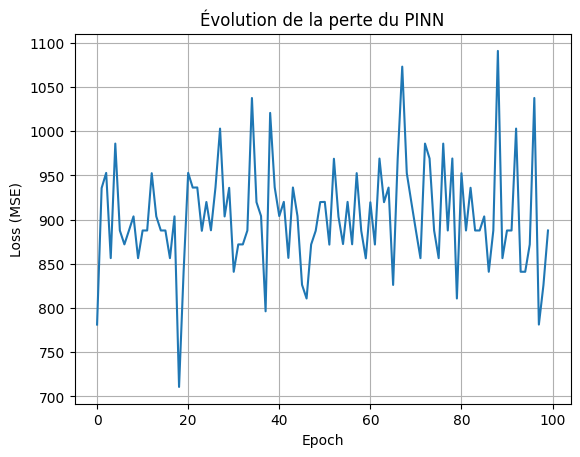

In [ ]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Évolution de la perte du PINN")
plt.grid(True)
plt.show()
# Visualisation des résultats

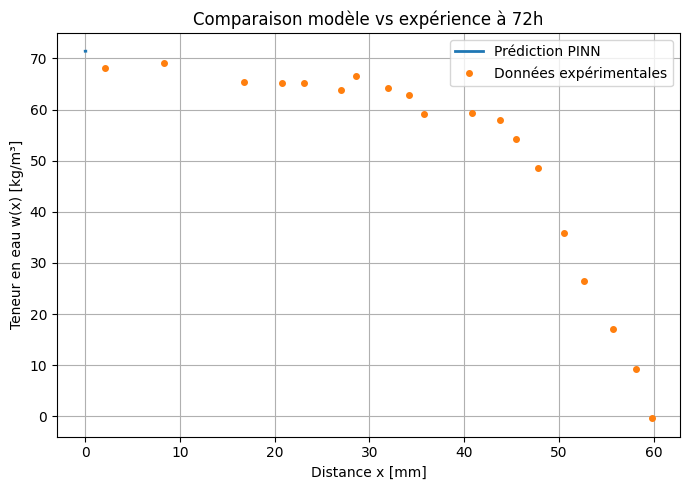

In [ ]:
D0 = model(normalize(input_tensor))
Dv = tf.squeeze(D0)
x_model, w_model = simulate_model_tf(Dv, 0.6, 0.119, 1000.0, 1e-3, 100.0, 72.0*3600, 60)

plt.figure(figsize=(7, 5))
plt.plot(x_model.numpy(), w_model.numpy(), label="Prédiction PINN", lw=2)
plt.plot(x_exp.numpy(), w_exp.numpy(), 'o', label="Données expérimentales", markersize=4)
plt.xlabel("Distance x [mm]")
plt.ylabel("Teneur en eau w(x) [kg/m³]")
plt.title("Comparaison modèle vs expérience à 72h")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

df_results = pd.DataFrame({
    "x [mm]": x_model.numpy(),
    "w_prédit [kg/m³]": w_model.numpy(),
    "w_exp [kg/m³]": np.interp(x_model.numpy(), x_exp.numpy(), w_exp.numpy())
})

df_results.head(100)  # affiche les 10 premières lignes


,x [mm],w_prédit [kg/m³],w_exp [kg/m³]
0,0.000,71.398033,68.139999
1,0.001,71.398148,68.139999
2,0.002,71.398247,68.139999
3,0.003,71.398338,68.139999
4,0.004,71.398438,68.139999
5,0.005,71.398537,68.139999
6,0.006,71.398636,68.139999
7,0.007,71.398735,68.139999
8,0.008,71.398842,68.139999
9,0.009,71.398933,68.139999


In [ ]:
print(f"Epoch {epoch}, D0: {D0.numpy()[0][0]:.2e}, Loss: {loss.numpy():.4f}")

Epoch 99, D0: 2.15e+01, Loss: 887.6821


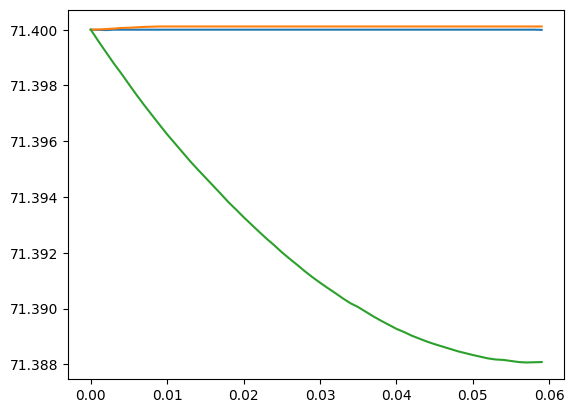

In [ ]:
for Dv_test in [1e-11, 5e-10, 1e-9]:
    x_test, w_test = simulate_model_tf(tf.constant(Dv_test), 0.6, 0.119, 1000.0, 1e-3, 100.0, 72.0*3600, 60)
    plt.plot(x_test.numpy(), w_test.numpy(), label=f"Dv={Dv_test:.0e}")